# Image Colorization — ResNet18-U-Net Fine-Tuning

Продолжим обучение **лучшей ResNet18-U-Net без scheduler**, используя её сохранённый `best.pt`. В предыдущем эксперименте encoder был полностью заморожен, а сейчас разморозим только `layer4` для адаптации признаков к колоризации.

**Что не меняем:** архитектуру, датасет, L1 Loss и остальные слои encoder. **Что меняем:** разрешаем обучение `layer4` и задаём отдельные learning rate для encoder и decoder. Новый эксперимент сохраняется отдельно от предыдущего.

## 1. Setup

Запускаем ноутбук в Colab из корня `image-colorization`. Подготовка проекта и данных такая же, как в предыдущем эксперименте. Checkpoints храним на Google Drive.

In [1]:
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import wandb
from torch import nn
from skimage.color import lab2rgb

from image_colorization.resnet_unet import ResNetUNet
from image_colorization.dataloaders import create_dataloaders
from image_colorization.training import train_model
from image_colorization.color_utils import denormalize_lab

## 2. Experiment Configuration

In [20]:
NUM_EPOCHS = 20
BATCH_SIZE = 32
LR_ENCODER = 1e-5
LR_DECODER = 1e-4

experiment_name = "resnet18_unet_finetune_layer4"

config = {
    "architecture": "resnet18_unet",
    "encoder": "ResNet18",
    "pretrained": True,
    "finetune_layer": "layer4",
    "other_encoder_layers_frozen": True,
    "initial_checkpoint": "resnet18_unet_frozen_encoder_best.pt",
    "num_epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr_encoder": LR_ENCODER,
    "lr_decoder": LR_DECODER,
    "optimizer": "AdamW",
    "loss": "L1",
    "scheduler": "None"
}

## 3. Data Paths and Checkpoints

`source_best_path` — **старые веса**, с которых начинаем fine-tuning. `last_path` и `best_path` — **новые checkpoints** этого эксперимента. Пути не совпадают.

In [21]:
images_dir = Path("VOCdevkit/VOC2012/JPEGImages")
train_path = Path("data/splits/train.txt")
val_path = Path("data/splits/val.txt")

checkpoint_dir = Path("/content/drive/MyDrive/image-colorization/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

source_best_path = checkpoint_dir / "resnet18_unet_frozen_encoder_best.pt"
last_path = checkpoint_dir / f"{experiment_name}_last.pt"
best_path = checkpoint_dir / f"{experiment_name}_best.pt"

## 4. DataLoaders

In [22]:
train_loader, val_loader = create_dataloaders(
    images_dir=images_dir,
    train_path=train_path,
    val_path=val_path,
    batch_size=BATCH_SIZE,
)

## 5. Model and Optimizer

Загружаем `best.pt` обычной ResNet18-U-Net **до создания optimizer**. Затем размораживаем только `layer4`. Остальные слои encoder остаются замороженными, а decoder обучается с отдельным learning rate.

В `ResNetUNet.train()` BatchNorm encoder остаётся в режиме `eval`, но это не запрещает обновление обучаемых весов `layer4`.

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = ResNetUNet().to(device)
source_checkpoint = torch.load(source_best_path, map_location=device, weights_only=True)
model.load_state_dict(source_checkpoint["model_state_dict"])

for param in model.layer4.parameters():
    param.requires_grad = True

decoder_params = [p for name, p in model.named_parameters()
                  if p.requires_grad and not name.startswith("layer4.")]

optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": LR_ENCODER},
    {"params": decoder_params, "lr": LR_DECODER}
])
criterion = nn.L1Loss()

Device: cuda


## 6. Weights & Biases

In [12]:
import wandb

In [17]:
wandb.login(relogin=True)

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [24]:
run = wandb.init(
    entity="arzushkaB",
    project="image-colorization",
    name=experiment_name,
    config=config,
)

wandb: WARNING Fatal error while uploading data. Some run data will not be synced, but it will still be written to disk. Use `wandb sync` at the end of the run to try uploading.


## 7. Model Training

Продолжаем обучение **из старого лучшего checkpoint**, а не с нуля. `training.py` используем как раньше: без scheduler, с W&B и отдельными путями сохранения. Для этого эксперимента `learning_rate` в старом логировании `training.py` показывает LR первой группы (encoder); обе начальные скорости записаны в `config`.

In [25]:
train_losses, val_losses = train_model(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=NUM_EPOCHS,
    device=device,
    last_path=last_path,
    best_path=best_path,
    run=run
)

print(f"Train L1: {train_losses[-1]:.5f}")
print(f"Val L1: {val_losses[-1]:.5f}")
print(f"Best Val L1: {min(val_losses):.5f} (epoch {np.argmin(val_losses) + 1})")

run.finish()

Training:   0%|          | 0/20 [00:00<?, ?it/s]

Train L1: 0.04291
Val L1: 0.06254
Best Val L1: 0.05962 (epoch 1)


epoch,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
train_loss,█▇▇▆▆▅▅▄▄▃▃▃▂▂▂▂▂▁▁▁
val_loss,▁▁▂▂▄▄▅▅▆▅▇▆▇▇▆▆▇█▇▇
epoch,20
train_loss,0.04291
val_loss,0.06254


## 8. Checkpoints

Проверяем новые `best.pt` и `last.pt`, не затрагивая исходный checkpoint.

In [26]:
for name, path in (("best", best_path), ("last", last_path)):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    print(f"{name}: epoch {checkpoint['epoch']}, Val L1 {checkpoint['val_losses'][-1]:.5f}")

best: epoch 1, Val L1 0.05962
last: epoch 20, Val L1 0.06254


## 9. Training Curves

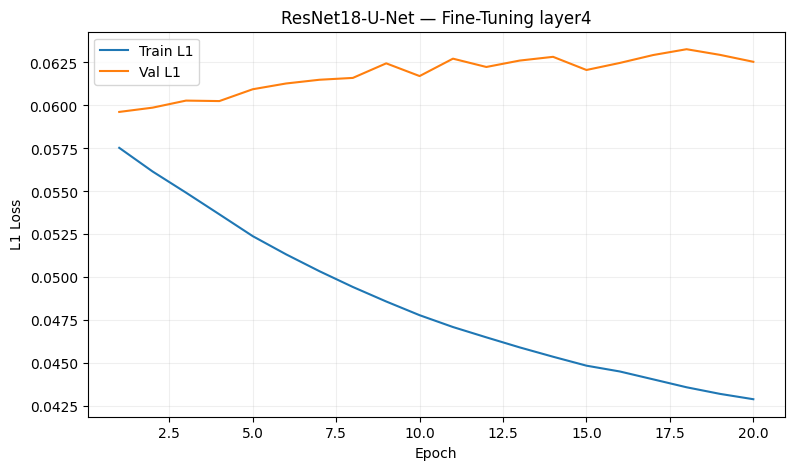

In [27]:
epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, label="Train L1")
plt.plot(epochs, val_losses, label="Val L1")
plt.xlabel("Epoch")
plt.ylabel("L1 Loss")
plt.title("ResNet18-U-Net — Fine-Tuning layer4")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 10. Best Model Evaluation

Загружаем лучший checkpoint **fine-tuning** и оцениваем его на том же фиксированном первом validation-батче, как в предыдущих ноутбуках.

In [28]:
best_checkpoint = torch.load(best_path, map_location=device, weights_only=True)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

L, ab = next(iter(val_loader))
with torch.no_grad():
    pred_ab = model(L.to(device)).cpu()

print("Best epoch:", best_checkpoint["epoch"])
print("Gray baseline L1:", criterion(torch.zeros_like(ab), ab).item())
print("ResNet18-U-Net Fine-Tuning L1:", criterion(pred_ab, ab).item())

Best epoch: 1
Gray baseline L1: 0.06412637233734131
ResNet18-U-Net Fine-Tuning L1: 0.06168067455291748
